# 1. Automatic tumor masks

The U-Net from the segmentation project was retrained on BraTS 2020 in 3 folds. Every patient's mask comes from the model of the fold that held that patient out, so no mask is drawn by a model that saw the patient during training.

Here I check how close these masks are to the expert masks, before using them for radiomics in notebook 2.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd

BRATS = Path("../../Glioma_Grade_Radiomics/data/brats2020")
AUTO = Path("../data/auto_masks")
FIGURES = Path("../results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

folds = pd.Series(json.loads(Path("../data/folds.json").read_text()), name="fold")
grade = pd.read_csv(BRATS / "name_mapping.csv").set_index("BraTS_2020_subject_ID")["Grade"]
pd.crosstab(folds, grade.reindex(folds.index))

Grade,HGG,LGG
fold,,
0,98,25
1,98,25
2,97,26


## Training

Each fold trained for 10 epochs on 222 patients, with 24 patients for picking the best epoch. Validation Dice is computed on 2D slices here, like in the U-Net project.

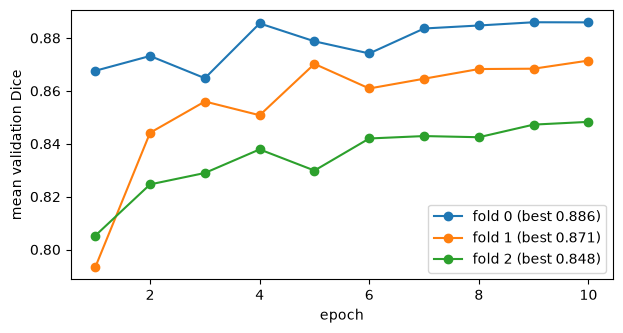

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in range(3):
    history = pd.DataFrame(json.loads(Path(f"../runs/fold{k}/history.json").read_text()))
    ax.plot(history["epoch"], history["mean"], marker="o", label=f"fold {k} (best {history['mean'].max():.3f})")
ax.set_xlabel("epoch")
ax.set_ylabel("mean validation Dice")
ax.legend()
plt.show()

All three folds reach most of their final score in the first epoch, so 10 epochs (instead of 30 in the U-Net project) was enough. Fold 2 ends a bit lower, mostly on the tumor core.

## Dice per patient on the full 3D volume

The validation numbers above are on 2D slices. For radiomics what matters is the whole 3D mask of each patient, so here I compare the predicted masks with the expert ones patient by patient, using the BraTS regions:

- **WT** whole tumor = labels 1, 2, 4
- **TC** tumor core = labels 1, 4
- **ET** enhancing tumor = label 4

When neither mask has any voxels of a region (e.g. ET in a non-enhancing LGG), the Dice is set to 1.

In [3]:
REGIONS = {"WT": [1, 2, 4], "TC": [1, 4], "ET": [4]}


def dice(a, b):
    total = a.sum() + b.sum()
    return 1.0 if total == 0 else 2 * (a & b).sum() / total


rows = []
for case in folds.index:
    expert = np.asarray(nib.load(BRATS / case / f"{case}_seg.nii.gz").dataobj)
    auto = np.asarray(nib.load(AUTO / f"{case}_seg.nii.gz").dataobj)
    row = {"case": case, "fold": folds[case], "grade": grade[case]}
    for region, labels in REGIONS.items():
        e, a = np.isin(expert, labels), np.isin(auto, labels)
        row[f"{region}_dice"] = dice(e, a)
        row[f"{region}_expert_cm3"] = e.sum() / 1000  # voxels are 1 mm^3
        row[f"{region}_auto_cm3"] = a.sum() / 1000
    rows.append(row)

per_patient = pd.DataFrame(rows).set_index("case")
per_patient.to_csv("../results/dice_per_patient.csv")
per_patient.head()

,fold,grade,WT_dice,WT_expert_cm3,WT_auto_cm3,TC_dice,TC_expert_cm3,TC_auto_cm3,ET_dice,ET_expert_cm3,ET_auto_cm3
case,,,,,,,,,,,
BraTS20_Training_001,0,HGG,0.918983,211.979,188.381,0.866385,43.185,54.169,0.857475,27.742,32.472
BraTS20_Training_002,2,HGG,0.876748,67.008,76.762,0.901239,15.709,18.029,0.806486,6.549,7.512
BraTS20_Training_003,2,HGG,0.747845,29.807,34.217,0.905534,3.731,3.732,0.844372,2.998,3.177
BraTS20_Training_004,0,HGG,0.925031,103.496,96.880,0.880138,26.400,22.206,0.847378,15.498,14.727
BraTS20_Training_005,1,HGG,0.596010,21.963,25.251,0.821783,14.410,11.390,0.723292,10.786,9.629


In [4]:
dice_cols = ["WT_dice", "TC_dice", "ET_dice"]
summary = pd.concat({
    "median": per_patient.groupby("grade")[dice_cols].median(),
    "mean": per_patient.groupby("grade")[dice_cols].mean(),
}).round(3)
summary.loc[("median", "all"), :] = per_patient[dice_cols].median().round(3)
summary.loc[("mean", "all"), :] = per_patient[dice_cols].mean().round(3)
summary.sort_index()

WT_dice  TC_dice  ET_dice
       grade                           
mean   HGG      0.886    0.849    0.810
       LGG      0.873    0.587    0.343
       all      0.883    0.795    0.714
median HGG      0.916    0.903    0.853
       LGG      0.898    0.659    0.307
       all      0.913    0.882    0.830

In [5]:
# In the radiomics project the strongest grade signal was "does the tumor enhance at all?".
# Does the U-Net get that right? (same 30-voxel threshold as the radiomics code)
enhancing = pd.DataFrame({
    "expert": per_patient["ET_expert_cm3"] * 1000 >= 30,
    "auto": per_patient["ET_auto_cm3"] * 1000 >= 30,
    "grade": per_patient["grade"],
})
pd.crosstab([enhancing["grade"], enhancing["expert"]], enhancing["auto"],
            rownames=["grade", "expert: enhancing"], colnames=["U-Net: enhancing"])

U-Net: enhancing         False  True 
grade expert: enhancing              
HGG   True                   0    293
LGG   False                  1     26
      True                   0     49

predicted ET where the expert has none (cm3):
count    27.00
mean      1.89
std       3.29
min       0.00
25%       0.26
50%       0.68
75%       2.03
max      16.46

predicted ET where the expert has ET, by grade (median cm3):
       ET_expert_cm3  ET_auto_cm3
grade                            
HGG            19.46        19.27
LGG             2.58         2.74


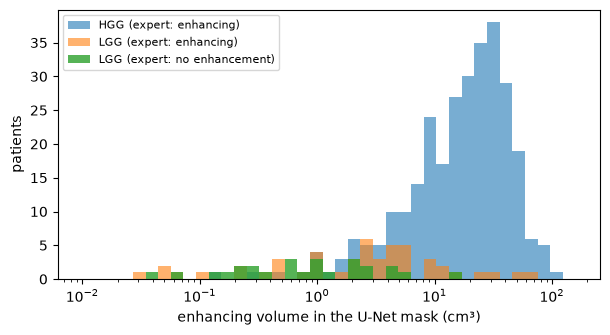

In [6]:
# The U-Net marks enhancing tumor in 26 of the 27 LGG that have none. How much?
false_et = per_patient.loc[~enhancing["expert"], "ET_auto_cm3"]
true_et = per_patient.loc[enhancing["expert"]]
print("predicted ET where the expert has none (cm3):")
print(false_et.describe().round(2).to_string())
print("\npredicted ET where the expert has ET, by grade (median cm3):")
print(true_et.groupby("grade")[["ET_expert_cm3", "ET_auto_cm3"]].median().round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(-2, 2.2, 40)
ax.hist(true_et.loc[true_et["grade"] == "HGG", "ET_auto_cm3"], bins=bins, alpha=0.6, label="HGG (expert: enhancing)")
ax.hist(true_et.loc[true_et["grade"] == "LGG", "ET_auto_cm3"], bins=bins, alpha=0.6, label="LGG (expert: enhancing)")
ax.hist(false_et, bins=bins, alpha=0.8, label="LGG (expert: no enhancement)")
ax.set_xscale("log")
ax.set_xlabel("enhancing volume in the U-Net mask (cm³)")
ax.set_ylabel("patients")
ax.legend(fontsize=8)
plt.show()

So far:

- **Whole tumor is segmented well for both grades** (median Dice ~0.91 for HGG, ~0.90 for LGG).
- **Tumor core and enhancing tumor are much worse for LGG.** The models were trained on ~80% HGG, and they mark a small enhancing region in **26 of the 27 LGG that don't enhance at all**.
- These false regions are small (median 0.7 cm³), while HGG enhancement is around 19 cm³. So the yes/no "enhancing or not" signal from the radiomics project is gone with automatic masks, but the *amount* of enhancement still separates the grades.

This is exactly the kind of error that can change downstream results, so notebook 2 compares the grade model on both mask types.

## Worst cases

In [7]:
per_patient.sort_values("WT_dice")[["grade", "fold", "WT_dice", "WT_expert_cm3", "WT_auto_cm3"]].head(6).round(3)

,grade,fold,WT_dice,WT_expert_cm3,WT_auto_cm3
case,,,,,
BraTS20_Training_325,LGG,0,0.287,17.082,7.313
BraTS20_Training_086,HGG,0,0.352,20.752,7.131
BraTS20_Training_087,HGG,0,0.392,26.806,7.691
BraTS20_Training_046,HGG,2,0.433,36.342,16.630
BraTS20_Training_277,LGG,0,0.550,30.073,21.447
BraTS20_Training_110,HGG,1,0.584,15.762,17.566


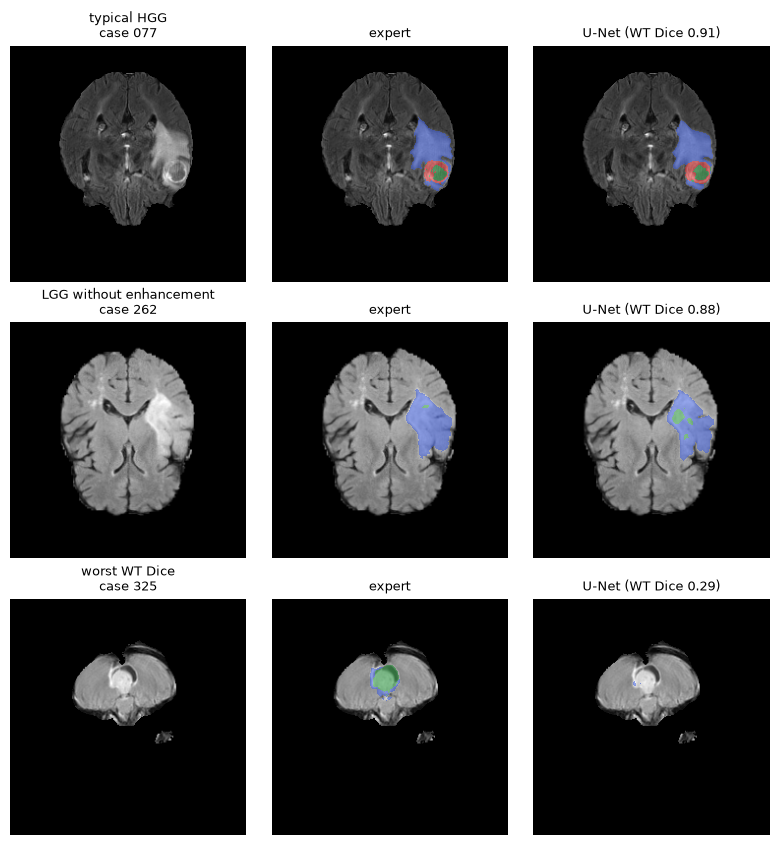

In [8]:
from matplotlib.colors import ListedColormap

# edema blue, non-enhancing green, enhancing red (same colors as the U-Net project figures)
LABEL_COLORS = ListedColormap(["#3b5bdb", "#2f9e44", "#e03131"])


def show_case(case, axes, title=""):
    flair = nib.load(BRATS / case / f"{case}_flair.nii.gz").get_fdata()
    expert = np.asarray(nib.load(BRATS / case / f"{case}_seg.nii.gz").dataobj)
    auto = np.asarray(nib.load(AUTO / f"{case}_seg.nii.gz").dataobj)
    z = np.argmax((expert > 0).sum(axis=(0, 1)))  # slice with the most tumor
    for ax, mask, name in zip(axes, [None, expert, auto], ["FLAIR", "expert", "U-Net"]):
        ax.imshow(np.rot90(flair[:, :, z]), cmap="gray")
        if mask is not None:
            m = np.rot90(mask[:, :, z]).astype(float)
            m = np.select([m == 2, m == 1, m == 4], [0, 1, 2], np.nan)  # edema, non-enhancing, enhancing
            ax.imshow(m, cmap=LABEL_COLORS, vmin=0, vmax=2, alpha=0.55, interpolation="nearest")
        ax.set_title(f"{name}{title if mask is not None and name == 'U-Net' else ''}", fontsize=9)
        ax.axis("off")


examples = {
    "typical HGG": per_patient[per_patient["grade"] == "HGG"]["WT_dice"].sub(per_patient["WT_dice"].median()).abs().idxmin(),
    "LGG without enhancement": false_et.sub(false_et.median()).abs().idxmin(),
    "worst WT Dice": per_patient["WT_dice"].idxmin(),
}
fig, axes = plt.subplots(3, 3, figsize=(8, 8.5))
for row, (label, case) in zip(axes, examples.items()):
    show_case(case, row, f" (WT Dice {per_patient.loc[case, 'WT_dice']:.2f})")
    row[0].set_title(f"{label}\n{case.replace('BraTS20_Training_', 'case ')}", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "segmentation_examples.png", dpi=130, bbox_inches="tight")
plt.show()

The worst case (325) is a tumor low in the brain, near the brainstem, which the models almost completely miss. Most training tumors are in the cerebral hemispheres, so this location is rare.

**Summary of the automatic masks** (369 patients, each predicted by a model that never saw them):

| | WT | TC | ET |
|---|---|---|---|
| median Dice, HGG | 0.92 | 0.90 | 0.85 |
| median Dice, LGG | 0.90 | 0.66 | 0.31 |

Whole tumor is close to the expert masks. Core and enhancing regions of LGG are not, mainly because the U-Net adds small enhancing regions to LGG that have none. Notebook 2 checks what this does to grade and survival prediction.